In [4]:
import numpy as np
import matplotlib.pyplot as plt

import glob
import csv

from pathlib import Path

from das_tools import maps
from das_tools.utils import proj_path

# ============================================================
# SETTINGS
# ============================================================
PROJECT_ROOT = proj_path.find_project_root()
DATA_ROOT = proj_path.data_dir()

# Use ONE satellite image for both panels
GEOTIFF_PATH = DATA_ROOT / "satellite" / "sentinel2_2025-05-06_original.tif"

KML_PATH = DATA_ROOT / "CableRoute2025_onice_traced_smoothed.kml"

# ------------------------------------------------------------
# ONE shared ROI
# ------------------------------------------------------------
# Half-widths in km around the selected cable point
HALF_SIZE_KM_LAT = 2.2
HALF_SIZE_KM_LON = 2.2

# Ice-thickness limits
ICE_VMIN = 0.5
ICE_VMAX = 4.0

# Appearance
CABLE_COLOR = "red"
CABLE_LINEWIDTH = 4.0

plt.rcParams.update({
    "text.usetex": True,
    "font.family": "serif",
    "font.size": 18,
    "axes.titlesize": 22,
    "axes.labelsize": 18,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "text.latex.preamble": r"\usepackage{amsmath}\usepackage{amssymb}\usepackage{times}",
})

FIGURE_DIR = Path("figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

OUT_PDF = FIGURE_DIR / "satellite_cable_icethickness.pdf"


In [5]:
# ============================================================
# Wind: SWIFT19 telemetry
# ============================================================

import xarray as xr

WIND_PATH = DATA_ROOT / "SWIFT19_telemetry.nc"

# Same window as das_tools.processing.pisces25_telemetry.retrieve_wind_swift
WIND_START = "2025-04-24 00:00:00"
WIND_END = "2025-05-08 00:00:00"

WIND_COLOR = "orange"
DARK_ORANGE = "#D55E00"
with xr.open_dataset(WIND_PATH) as ds_wind:
    ds_wind = ds_wind.sel(time=slice(WIND_START, WIND_END))
    wind_dir = ds_wind["winddirR"].values    # direction wind blows FROM (deg, clockwise from N)
    wind_spd = ds_wind["wind_speed"].values  # m/s

valid = np.isfinite(wind_dir) & np.isfinite(wind_spd)
wind_dir = wind_dir[valid]
wind_spd = wind_spd[valid]

# Speed-weighted circular mean of the "from" direction
theta_w = np.deg2rad(wind_dir)
u_sum = np.sum(wind_spd * np.sin(theta_w))
v_sum = np.sum(wind_spd * np.cos(theta_w))

WIND_AZIMUTH = np.rad2deg(np.arctan2(u_sum, v_sum)) % 360
wind_steadiness = np.hypot(u_sum, v_sum) / np.sum(wind_spd)  # 1 = perfectly steady
wind_spd_median = np.median(wind_spd)

print(f"Wind samples      : {wind_dir.size}")
print(f"Dominant wind from: {WIND_AZIMUTH:.1f} deg")
print(f"Steadiness (R)    : {wind_steadiness:.3f}")
print(f"Median speed      : {wind_spd_median:.1f} m/s")


def point_outside_box(box_x, box_y, azimuth_deg, gap):
    """
    Point just outside the box edge that faces `azimuth_deg`
    (0 deg = north, clockwise), `gap` map units beyond the edge.
    """
    cx = 0.5 * (np.min(box_x) + np.max(box_x))
    cy = 0.5 * (np.min(box_y) + np.max(box_y))
    half_w = 0.5 * (np.max(box_x) - np.min(box_x))
    half_h = 0.5 * (np.max(box_y) - np.min(box_y))

    theta = np.deg2rad(azimuth_deg)
    direction = np.array([np.sin(theta), np.cos(theta)])

    # Distance from box center to its edge along `direction`
    with np.errstate(divide="ignore"):
        t_edge = min(half_w / abs(direction[0]), half_h / abs(direction[1]))

    return np.array([cx, cy]) + direction * (t_edge + gap)


Wind samples      : 312
Dominant wind from: 60.4 deg
Steadiness (R)    : 0.987
Median speed      : 6.0 m/s


Reference cable point:
    lon = -156.676469
    lat = 71.347125

Shared ROI:
    longitude: -156.738260 to -156.614678
    latitude : 71.327229 to 71.367021

Satellite CRS: EPSG:3857
Image extent: [-17448023.30553782, -17434283.30553782, 11515108.354198806, 11528948.354198806]
[-17442419.82692933  11522699.97045165]
ROI projected coordinates:
x: [-17442082.72639754 -17439268.79230926 -17439268.79230926
 -17442082.72639754 -17442082.72639754]
y: [11520131.5085634  11520131.5085634  11522964.12277677 11522964.12277677
 11520131.5085634 ]


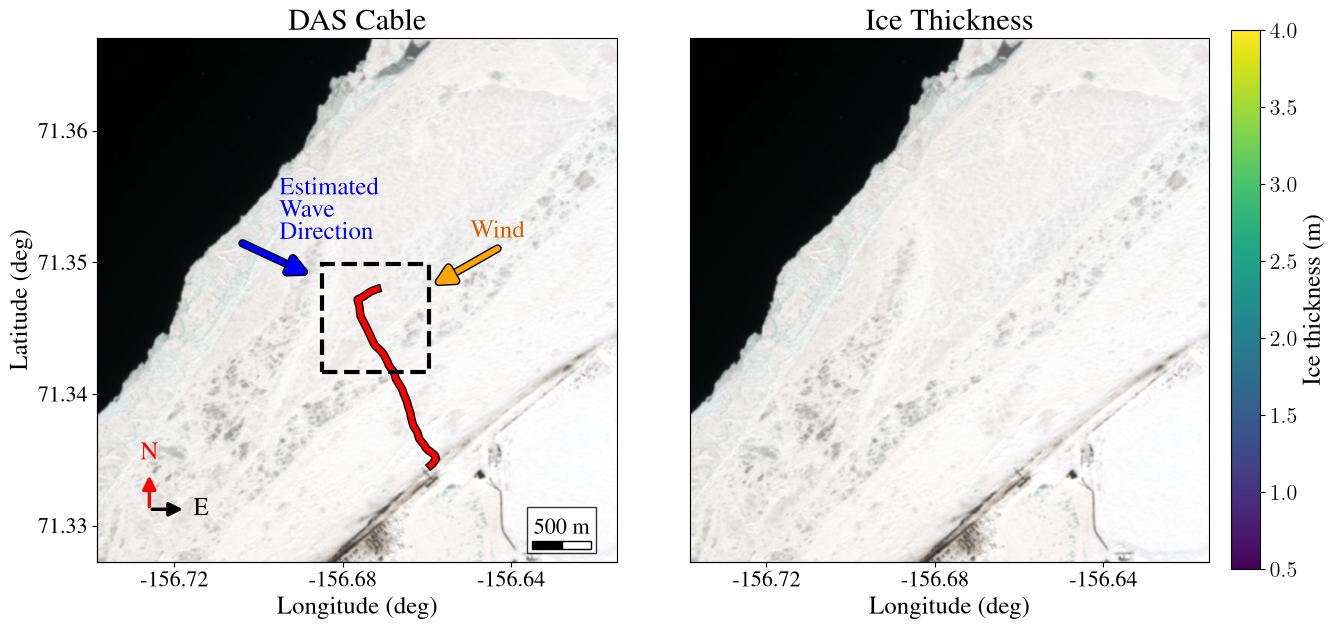

In [6]:
# ============================================================
# 1. READ CABLE
# ============================================================

lon, lat = maps.read_kml_lonlat(KML_PATH)

# Use the same reference point that the current notebooks use:
# left-most point of the cable
i0 = int(np.argmin(lon))
lon0 = float(lon[i0])
lat0 = float(lat[i0])

print(f"Reference cable point:")
print(f"    lon = {lon0:.6f}")
print(f"    lat = {lat0:.6f}")


# ============================================================
# 2. ONE COMMON LAT/LON ROI, 3. SATELLITE IMAGE CROPPED TO IT
# ============================================================

lon_min, lon_max, lat_min, lat_max = maps.lonlat_box(lon0, lat0, HALF_SIZE_KM_LON, HALF_SIZE_KM_LAT)
print("\nShared ROI:")
print(f"    longitude: {lon_min:.6f} to {lon_max:.6f}")
print(f"    latitude : {lat_min:.6f} to {lat_max:.6f}")

bm = maps.load_basemap(GEOTIFF_PATH, lon_min, lon_max, lat_min, lat_max, stretch=(0, 98))
print("\nSatellite CRS:", bm.crs)
print("Image extent:", bm.extent)

x_cab, y_cab = bm.xy(lon, lat)


# ============================================================
# 6. LOAD ICE THICKNESS
# ============================================================

dataDir = DATA_ROOT / "ice_thickness"

data_filenames = sorted(
    glob.glob(str(dataDir / "*TT.csv"))
)

lat_ice = []
lon_ice = []
TT = []

for filename in data_filenames:

    with open(filename, "r", newline="") as iceFile:

        csv_reader = csv.reader(iceFile)

        header = next(csv_reader)

        if filename[-34:-32] == "EM":

            for row in csv_reader:

                lat_ice.append(float(row[4]))
                lon_ice.append(float(row[5]))
                TT.append(float(row[6]))

        else:

            for row in csv_reader:

                if row[3] == "":
                    continue

                lat_ice.append(float(row[3]))
                lon_ice.append(float(row[4]))
                TT.append(float(row[6]))

lat_ice = np.asarray(lat_ice, dtype=float)
lon_ice = np.asarray(lon_ice, dtype=float)
TT = np.asarray(TT, dtype=float)

x_ice, y_ice = bm.xy(lon_ice, lat_ice)


# ============================================================
# 7. CREATE TWO PANELS WITH IDENTICAL PLOTTING AREAS
# ============================================================

fig = plt.figure(
    figsize=(15, 7),
)

# Four columns:
#
#   image | colorbar | image | colorbar
#
# Both image axes therefore have EXACTLY the same size.
gs = fig.add_gridspec(
    nrows=1,
    ncols=4,
    width_ratios=[1.0, 0.055, 1.0, 0.055],
    wspace=0.08,
)

ax1 = fig.add_subplot(gs[0, 0])
cax1 = fig.add_subplot(gs[0, 1])

ax2 = fig.add_subplot(gs[0, 2])
cax2 = fig.add_subplot(gs[0, 3])


# ============================================================
# 8. LEFT: SATELLITE + CABLE ONLY
# ============================================================

bm.show(ax1)
ax1.plot(x_cab, y_cab, color=CABLE_COLOR, linewidth=CABLE_LINEWIDTH, zorder=5,
         path_effects=maps.halo(CABLE_LINEWIDTH + 2, "black"))
ax1.set_title("DAS Cable")


# ============================================================
# ROI from overlay_DAS_on_sentinel_geotiff_roi_deg_zoom2_with_ice
# ============================================================

from matplotlib.patches import Polygon

roi_lon_min = -156.684895
roi_lon_max = -156.659617
roi_lat_min = 71.341699
roi_lat_max = 71.349838

# Four geographic corners
roi_lon = np.array([roi_lon_min, roi_lon_max, roi_lon_max, roi_lon_min, roi_lon_min])
roi_lat = np.array([roi_lat_min, roi_lat_min, roi_lat_max, roi_lat_max, roi_lat_min])

# Transform ALL corners into the GeoTIFF CRS
roi_x, roi_y = bm.xy(roi_lon, roi_lat)

roi_center = np.array([
    np.mean(roi_x[:4])*1.0001,
    np.mean(roi_y[:4])*1.0001,
])
print(roi_center)

arrow_length = 0.1 * np.hypot(*bm.size)

# Waves from 295 deg: the arrow travels towards 295 + 180 and ends at the ROI centre.
maps.add_azimuth_arrow(ax1, roi_center, 295 + 180, arrow_length, color="blue",
                       linewidth=4, mutation_scale=28, zorder=30)
txt = ax1.text(
    0.35,
    0.67,
    "Estimated\nWave\nDirection",
    transform=ax1.transAxes,
    color="blue",
    fontsize=18,
    ha="left",
    va="center",
)
txt.set_path_effects(maps.halo(1))

# Dominant wind direction: arrow comes from upwind and points at the ROI
wind_head = point_outside_box(
    roi_x[:4],
    roi_y[:4],
    azimuth_deg=WIND_AZIMUTH,
    gap=150,
)

maps.add_azimuth_arrow(ax1, wind_head, WIND_AZIMUTH + 180, arrow_length, color=WIND_COLOR,
                       linewidth=4, mutation_scale=28, zorder=30)

theta_wind = np.deg2rad(WIND_AZIMUTH)
wind_tail = wind_head + arrow_length * np.array([
    np.sin(theta_wind),
    np.cos(theta_wind),
])

txt = ax1.text(
    wind_tail[0],
    wind_tail[1] + 150,
    "Wind",
    color=DARK_ORANGE,
    fontsize=18,
    ha="center",
    va="bottom",
    zorder=31,
)
print("ROI projected coordinates:")
print("x:", roi_x)
print("y:", roi_y)

# Draw ROI on LEFT image
ax1.add_patch(Polygon(
    np.column_stack([roi_x, roi_y]),
    closed=True,
    fill=False,
    edgecolor="black",
    linewidth=3.0,
    linestyle="--",
    zorder=20,
))

maps.add_ne_arrows(ax1, fontsize=18)
maps.add_scalebar(ax1, bm, 500, corner="lower right", pad=(0.05, 0.025), fontsize=16)


# ============================================================
# 9. RIGHT: SATELLITE + ICE THICKNESS
# ============================================================

bm.show(ax2)
sc = ax2.scatter(
    x_ice,
    y_ice,
    c=TT,
    vmin=ICE_VMIN,
    vmax=ICE_VMAX,
    cmap="viridis",
    s=14,
    zorder=4,
)
ax2.set_title("Ice Thickness")


# ============================================================
# 10. COLORBAR
# ============================================================

cb = fig.colorbar(sc, cax=cax2)
cb.set_label("Ice thickness (m)")

# LEFT COLORBAR COLUMN IS INTENTIONALLY EMPTY
cax1.axis("off")


# ============================================================
# 11. LAT/LON AXES: longitude on both panels, latitude on the left one only
# ============================================================

maps.add_lonlat_axes(ax1, bm, lon_step=0.04, lat_step=0.01, lon_decimals=2, lat_decimals=2,
                     rotate_lat_labels=False)
maps.add_lonlat_axes(ax2, bm, lon_step=0.04, lat_step=None, lon_decimals=2)


fig.savefig(OUT_PDF, dpi=300, bbox_inches="tight")

plt.show()